## 1. Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib as Path
import warnings
warnings.filterwarnings('ignore')

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

print('All libraries imported succefully')

All libraries imported succefully


## 2. Define Project Paths

In [5]:
from pathlib import Path
def find_project_root():
    current = Path.cwd()

    for path in [current] + list(current.parents):
        if (path / 'pyproject.toml').exists():
            return path

    raise FileNotFoundError(
        "Project root could not be found. "
        "Make sure pyproject.toml exists in the project root."
    )

PROJECT_ROOT = find_project_root()

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "proccessed"
REJECTED_DIR = PROJECT_ROOT / "data" / "rejected"

RAW_FILE = RAW_DIR / "Telco_customer_churn.xlsx"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REJECTED_DIR.mkdir(parents=True, exist_ok=True)

print('Project root: ', PROJECT_ROOT)
print('Raw data: ', RAW_FILE)
print('Processed data: ', PROCESSED_DIR)

Project root:  c:\Projects\Original_AWS_Project\churn_predictor
Raw data:  c:\Projects\Original_AWS_Project\churn_predictor\data\raw\Telco_customer_churn.xlsx
Processed data:  c:\Projects\Original_AWS_Project\churn_predictor\data\proccessed


## 3. Load the Raw Dataset

In [6]:
if not RAW_FILE.exists():
    raise FileNotFoundError(f'Dataset not found: {RAW_FILE}')

df = pd.read_excel(RAW_FILE, sheet_name='Telco_Churn')

df_raw = df.copy()

print('Dataset loaded succefuly.')
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

Dataset loaded succefuly.
Rows    : 7,043
Columns : 33


## 4. Initial Dataset Inspection

In [7]:
print("Dataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

Dataset shape:
(7043, 33)

First 5 rows:


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [8]:
print("Last 5 rows:")
display(df.tail())

Last 5 rows:


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,No,No,No,72,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN
7042,3186-AJIEK,1,United States,California,Apple Valley,92308,"34.424926, -117.184503",34.424926,-117.184503,Male,No,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No,0,38,5097,NaN


In [9]:
print('Column names: ')
for i, column in enumerate(df.columns, start=1):
    print(f'{i:02d}. {column}')

Column names: 
01. CustomerID
02. Count
03. Country
04. State
05. City
06. Zip Code
07. Lat Long
08. Latitude
09. Longitude
10. Gender
11. Senior Citizen
12. Partner
13. Dependents
14. Tenure Months
15. Phone Service
16. Multiple Lines
17. Internet Service
18. Online Security
19. Online Backup
20. Device Protection
21. Tech Support
22. Streaming TV
23. Streaming Movies
24. Contract
25. Paperless Billing
26. Payment Method
27. Monthly Charges
28. Total Charges
29. Churn Label
30. Churn Value
31. Churn Score
32. CLTV
33. Churn Reason


## 7. Dataset Information

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [11]:
dtype_summery = pd.DataFrame({
    'Column': df.columns,
    'Data_Type': df.dtypes.astype(str),
    'Non_Null_Count': df.notna().sum().values,
    'Missing_Count': df.isna().sum().values,
    'Unique_Values': df.nunique(dropna=True).values
})

display(dtype_summery)

,Column,Data_Type,Non_Null_Count,Missing_Count,Unique_Values
CustomerID,CustomerID,str,7043,0,7043
Count,Count,int64,7043,0,1
Country,Country,str,7043,0,1
State,State,str,7043,0,1
City,City,str,7043,0,1129
Zip Code,Zip Code,int64,7043,0,1652
Lat Long,Lat Long,str,7043,0,1652
Latitude,Latitude,float64,7043,0,1652
Longitude,Longitude,float64,7043,0,1651
Gender,Gender,str,7043,0,2


## 8. Check Missing Values

In [12]:
missing_report = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isna().sum().values,
    "Missing_Percentage": (df.isna().sum().values / len(df) * 100).round(2)
})

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
].sort_values("Missing_Count", ascending=False)

display(missing_report)

,Column,Missing_Count,Missing_Percentage
32,Churn Reason,5174,73.46


For churn_reason, do not blindly impute the 5,174 missing values.
They correspond to non-churned customers for whom a churn reason is not
applicable. The column is also excluded from predictive features because
it can leak the outcome.

## 9. Check Blank Strings

In [13]:
blank_report = []

for column in df.select_dtypes(include="object").columns:
    blank_count = (
        df[column]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    )

    if blank_count > 0:
        blank_report.append({
            "Column": column,
            "Blank_Count": blank_count
        })

blank_report = pd.DataFrame(blank_report)

if not blank_report.empty:
    display(blank_report)
else:
    print("No blank string values found.")

,Column,Blank_Count
0,Total Charges,11


## 10. Check duplicates

In [14]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [15]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (7043, 33)


## 11. Check duplicate Customer IDs

Because CustomerID should identify one customer uniquely:

In [16]:
print("Unique Customer IDs:", df["CustomerID"].nunique())
print("Total rows:", len(df))

Unique Customer IDs: 7043
Total rows: 7043


In [17]:
duplicate_ids = df["CustomerID"].duplicated().sum()

print("Duplicate Customer IDs:", duplicate_ids)

Duplicate Customer IDs: 0


## 12. Identify constant columns

In [18]:
constant_columns = [
    column for column in df.columns
    if df[column].nunique() <= 1
]

print("Constant columns:")
print(constant_columns)

Constant columns:
['Count', 'Country', 'State']


These columns don't provide useful predictive information because they contain only one value. Therefore:

In [19]:
df = df.drop(columns=constant_columns)
print(df.shape)

(7043, 30)


## 13. Clean Total Charges

In [20]:
df["Total Charges"].dtype

dtype('O')

#### Convert to numeric

In [21]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors='coerce')

In [22]:
print(df["Total Charges"].dtype)

float64


#### Investigate missing Total Charges

In [23]:
df[df["Total Charges"].isnull()][
    ["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges"]
]

,CustomerID,Tenure Months,Monthly Charges,Total Charges
2234,4472-LVYGI,0,52.55,NaN
2438,3115-CZMZD,0,20.25,NaN
2568,5709-LVOEQ,0,80.85,NaN
2667,4367-NUYAO,0,25.75,NaN
2856,1371-DWPAZ,0,56.05,NaN
4331,7644-OMVMY,0,19.85,NaN
4687,3213-VVOLG,0,25.35,NaN
5104,2520-SGTTA,0,20.00,NaN
5719,2923-ARZLG,0,19.70,NaN
6772,4075-WKNIU,0,73.35,NaN


In [24]:
blank_total_charges = (
    df["Total Charges"]
    .astype(str)
    .str.strip()
    .eq("")
)

print("Blank Total Charges:", blank_total_charges.sum())

Blank Total Charges: 0


## 14. Handle missing Total Charges

In [25]:
df["Total Charges"] = df["Total Charges"].fillna(0)

In [26]:
print("Missing Total Charges:", df["Total Charges"].isnull().sum())

Missing Total Charges: 0


```text 
Why is 0 reasonable?
```
A customer with zero months of tenure has not accumulated a previous total charge in this dataset's representation.
This is better than using the mean or median because mean imputation would create an artificial spending value.

## 15. Clean Churn Reason

In [27]:
pd.crosstab(df["Churn Label"], df["Churn Reason"].isna())

Churn Reason,False,True
Churn Label,,
No,0,5174
Yes,1869,0


In here we can see that the missing churn reasons correspond to customers who didn't churn. Therefore, don't drop these rows.

#### Replace with meaningful category

In [28]:
df["Churn Reason"] = df["Churn Reason"].fillna(
    "Not Applicable"
)

In [29]:
df.isnull().sum()

CustomerID           0
City                 0
Zip Code             0
Lat Long             0
Latitude             0
Longitude            0
Gender               0
Senior Citizen       0
Partner              0
Dependents           0
Tenure Months        0
Phone Service        0
Multiple Lines       0
Internet Service     0
Online Security      0
Online Backup        0
Device Protection    0
Tech Support         0
Streaming TV         0
Streaming Movies     0
Contract             0
Paperless Billing    0
Payment Method       0
Monthly Charges      0
Total Charges        0
Churn Label          0
Churn Value          0
Churn Score          0
CLTV                 0
Churn Reason         0
dtype: int64

## 16. Check categorical inconsistencies

In [30]:
categorical_columns = df.select_dtypes(
    include='object'
).columns

for column in categorical_columns:
    print('\n', column)
    print(df[column].unique())


 CustomerID
<StringArray>
['3668-QPYBK', '9237-HQITU', '9305-CDSKC', '7892-POOKP', '0280-XJGEX',
 '4190-MFLUW', '8779-QRDMV', '1066-JKSGK', '6467-CHFZW', '8665-UTDHZ',
 ...
 '0871-OPBXW', '3605-JISKB', '9767-FFLEM', '8456-QDAVC', '7750-EYXWZ',
 '2569-WGERO', '6840-RESVB', '2234-XADUH', '4801-JZAZL', '3186-AJIEK']
Length: 7043, dtype: str

 City
<StringArray>
[    'Los Angeles',   'Beverly Hills', 'Huntington Park',         'Lynwood',
  'Marina Del Rey',       'Inglewood',    'Santa Monica',        'Torrance',
        'Whittier',        'La Habra',
 ...
      'Janesville',      'Litchfield',        'Loyalton',        'Madeline',
    'Markleeville',         'Milford',         'Calpine',        'Standish',
        'Tulelake',  'Olympic Valley']
Length: 1129, dtype: str

 Lat Long
<StringArray>
['33.964131, -118.272783',  '34.059281, -118.30742', '34.048013, -118.293953',
 '34.062125, -118.315709', '34.039224, -118.266293', '34.066367, -118.309868',
  '34.02381, -118.156582', '34.066303, 

## 17. Remove leading/trailing whitespace

In [31]:
object_columns = df.select_dtypes(
    include="object"
).columns

for column in object_columns:
    df[column] = df[column].str.strip()

In [32]:
for column in object_columns:
    print(column, df[column].unique()[:10])

CustomerID <StringArray>
['3668-QPYBK', '9237-HQITU', '9305-CDSKC', '7892-POOKP', '0280-XJGEX',
 '4190-MFLUW', '8779-QRDMV', '1066-JKSGK', '6467-CHFZW', '8665-UTDHZ']
Length: 10, dtype: str
City <StringArray>
[    'Los Angeles',   'Beverly Hills', 'Huntington Park',         'Lynwood',
  'Marina Del Rey',       'Inglewood',    'Santa Monica',        'Torrance',
        'Whittier',        'La Habra']
Length: 10, dtype: str
Lat Long <StringArray>
['33.964131, -118.272783',  '34.059281, -118.30742', '34.048013, -118.293953',
 '34.062125, -118.315709', '34.039224, -118.266293', '34.066367, -118.309868',
  '34.02381, -118.156582', '34.066303, -118.435479', '34.099869, -118.326843',
 '34.089953, -118.294824']
Length: 10, dtype: str
Gender <StringArray>
['Male', 'Female']
Length: 2, dtype: str
Senior Citizen <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Partner <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Dependents <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Phone Service <Stri

## 18. Check numerical outliers

In [33]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Zip Code,7043.0,93521.964646,1865.794555,90001.000000,92102.000000,93552.000000,95351.000000,96161.000000
Latitude,7043.0,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,-119.798880,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Tenure Months,7043.0,32.371149,24.559481,0.000000,9.000000,29.000000,55.000000,72.000000
Monthly Charges,7043.0,64.761692,30.090047,18.250000,35.500000,70.350000,89.850000,118.750000
Total Charges,7043.0,2279.734304,2266.794470,0.000000,398.550000,1394.550000,3786.600000,8684.800000
Churn Value,7043.0,0.265370,0.441561,0.000000,0.000000,0.000000,1.000000,1.000000
Churn Score,7043.0,58.699418,21.525131,5.000000,40.000000,61.000000,75.000000,100.000000
CLTV,7043.0,4400.295755,1183.057152,2003.000000,3469.000000,4527.000000,5380.500000,6500.000000


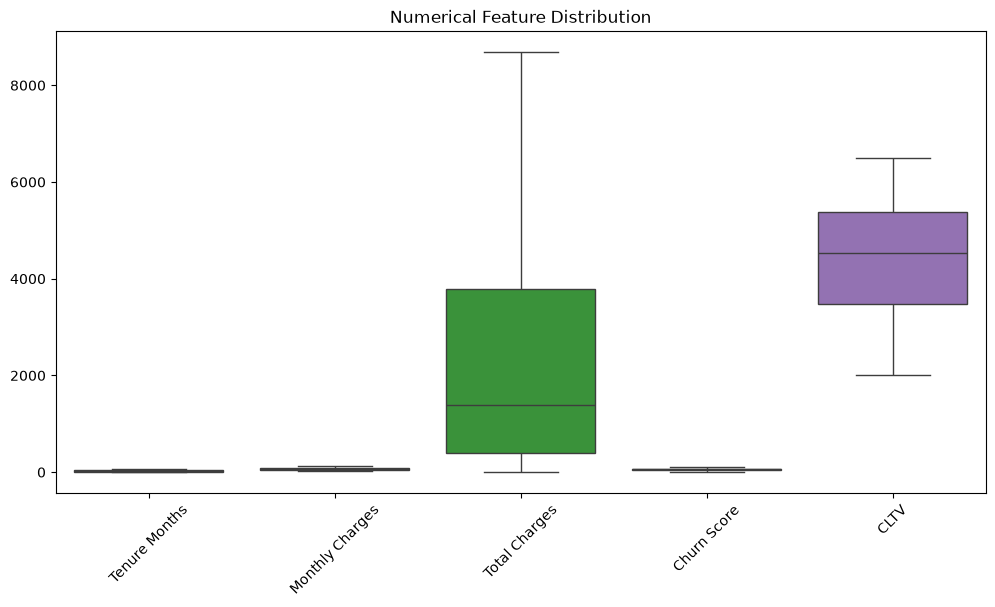

In [34]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[
        [
            "Tenure Months",
            "Monthly Charges",
            "Total Charges",
            "Churn Score",
            "CLTV"
        ]
    ]
)

plt.xticks(rotation=45)
plt.title("Numerical Feature Distribution")
plt.show()

In [35]:
numerical_columns = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "Churn Score",
    "CLTV"
]

outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier %": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,Tenure Months,9.00,55.00,46.00,-60.000,124.000,0,0.0
1,Monthly Charges,35.50,89.85,54.35,-46.025,171.375,0,0.0
2,Total Charges,398.55,3786.60,3388.05,-4683.525,8868.675,0,0.0
3,Churn Score,40.00,75.00,35.00,-12.500,127.500,0,0.0
4,CLTV,3469.00,5380.50,1911.50,601.750,8247.750,0,0.0


There are no outliers

## 19. Check numerical relationships

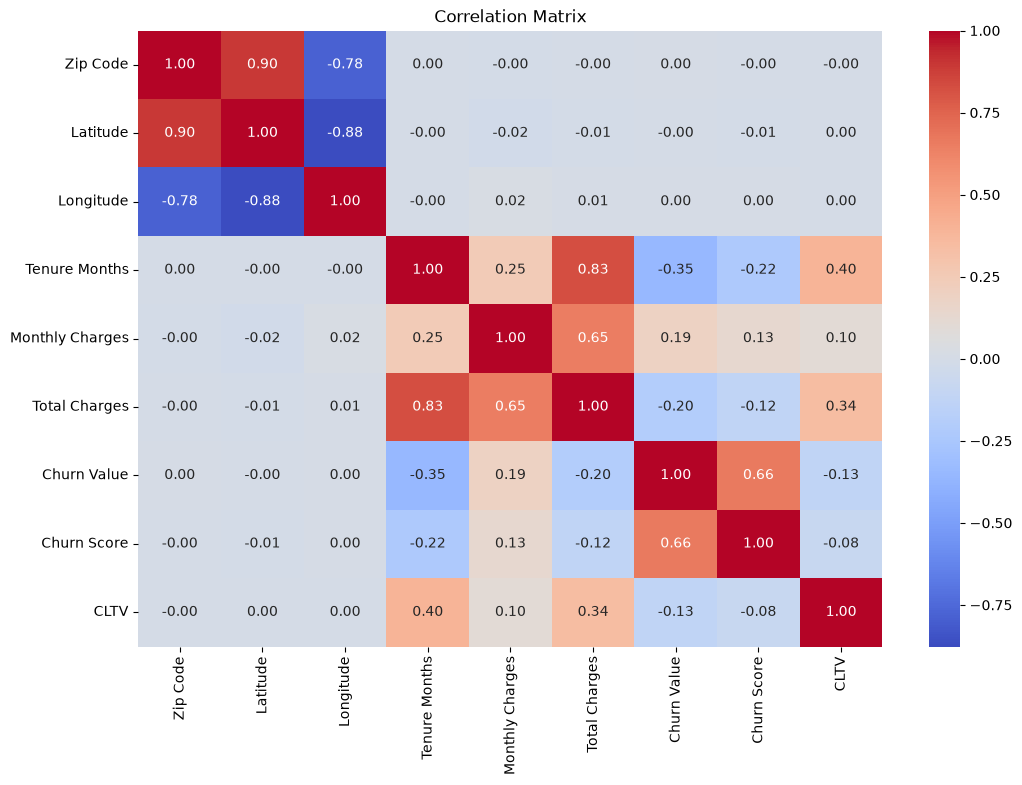

In [36]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

The correlation analysis identified a strong positive relationship between tenure months and total charges (r = 0.83), indicating that customers with longer service periods tend to accumulate higher total charges. Monthly charges also showed a moderate positive correlation with total charges (r = 0.65). Tenure months had a moderate negative relationship with churn value (r = −0.35), while monthly charges showed a weak positive relationship (r = 0.19). The churn score showed a strong correlation with churn value (r = 0.66); however, it was excluded from the predictive feature set due to the possibility of target leakage.

## 20. Target variable transformation

In [37]:
print(df["Churn Value"].value_counts())

Churn Value
0    5174
1    1869
Name: count, dtype: int64


In [38]:
print(df["Churn Label"].value_counts())

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64


#### Validate

In [39]:
mapping_check = (
    df["Churn Label"].map({
        "No": 0,
        "Yes": 1
    })
    == df["Churn Value"]
)

print("Target consistency:", mapping_check.all())

Target consistency: True


## 21. Feature engineering: Tenure groups

In [40]:
df["Tenure Group"] = pd.cut(
    df["Tenure Months"],
    bins=[-1, 12, 24, 48, 60, np.inf],
    labels=[
        "0-1 Year",
        "1-2 Years",
        "2-4 Years",
        "4-5 Years",
        "5+ Years"
    ]
)

In [41]:
df["Tenure Group"].value_counts()

Tenure Group
0-1 Year     2186
2-4 Years    1594
5+ Years     1407
1-2 Years    1024
4-5 Years     832
Name: count, dtype: int64

This is useful for exploratory analysis.

## 22. Monthly charge groups

In [42]:
df["Monthly Charge Group"] = pd.cut(
    df["Monthly Charges"],
    bins=[-np.inf, 30, 60, 90, np.inf],
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

However, don't necessarily use both the original and grouped feature in the final ML model without justification.

## 23. Transform binary categorical variables

In [43]:
binary_columns = [
    "Senior Citizen",
    "Partner",
    "Dependents",
    "Phone Service",
    "Paperless Billing"
]

for column in binary_columns:
    df[column] = df[column].map({
        "No": 0,
        "Yes": 1
    })

In [44]:
df[binary_columns].head()

,Senior Citizen,Partner,Dependents,Phone Service,Paperless Billing
0,0,0,0,1,1
1,0,0,1,1,1
2,0,0,1,1,1
3,0,1,1,1,1
4,0,0,1,1,1


## 24. One-hot encode categorical variables

In [45]:
categorical_features = [
    "City",
    "Gender",
    "Multiple Lines",
    "Internet Service",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies",
    "Contract",
    "Payment Method"
]

In [46]:
df = pd.get_dummies(
    df,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

## 25. Remove unwanted columns

In [47]:
columns_to_remove = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "Churn Label",
    "Churn Score",
    "Tenure Group",
    "Monthly Charge Group",
    "Lat Long",
    "Zip Code"
]

df = df.drop(columns=columns_to_remove, errors="ignore")

In [48]:
df

Latitude   Longitude  Senior Citizen  Partner  Dependents  \
0     33.964131 -118.272783               0        0           0   
1     34.059281 -118.307420               0        0           1   
2     34.048013 -118.293953               0        0           1   
3     34.062125 -118.315709               0        1           1   
4     34.039224 -118.266293               0        0           1   
...         ...         ...             ...      ...         ...   
7038  34.341737 -116.539416               0        0           0   
7039  34.667815 -117.536183               0        1           1   
7040  34.559882 -115.637164               0        1           1   
7041  34.167800 -116.864330               0        1           1   
7042  34.424926 -117.184503               0        0           0   

      Tenure Months  Phone Service  Paperless Billing  Monthly Charges  \
0                 2              1                  1            53.85   
1                 2              1                  1            70.70   
2                 8              1                  1            99.65   
3                28              1                  1           104.80   
4                49              1                  1           103.70   
...             ...            ...                ...              ...   
7038             72              1                  1            21.15   
7039             24              1                  1            84.80   
7040             72              1                  1           103.20   
7041             11              0                  1            29.60   
7042             66              1                  1           105.65   

      Total Charges  Churn Value  CLTV                   Churn Reason  \
0            108.15            1  3239   Competitor made better offer   
1            151.65            1  2701                          Moved   
2            820.50            1  5372                          Moved   
3           3046.05            1  5003                          Moved   
4           5036.30            1  5340  Competitor had better devices   
...             ...          ...   ...                            ...   
7038        1419.40            0  5306                 Not Applicable   
7039        1990.50            0  2140                 Not Applicable   
7040        7362.90            0  5560                 Not Applicable   
7041         346.45            0  2793                 Not Applicable   
7042        6844.50            0  5097                 Not Applicable   

      City_Acton  City_Adelanto  City_Adin  City_Agoura Hills  City_Aguanga  \
0              0              0          0                  0             0   
1              0              0          0                  0             0   
2              0              0          0                  0             0   
3              0              0          0                  0             0   
4              0              0          0                  0             0   
...          ...            ...        ...                ...           ...   
7038           0              0          0                  0             0   
7039           0              1          0                  0             0   
7040           0              0          0                  0             0   
7041           0              0          0                  0             0   
7042           0              0          0                  0             0   

      City_Ahwahnee  City_Alameda  City_Alamo  City_Albany  City_Albion  \
0                 0             0           0            0            0   
1                 0             0           0            0            0   
2                 0             0           0            0            0   
3                 0             0           0            0            0   
4                 0             0           0            0            0   
...             ...      

## 26. Save Processed Dataset

In [49]:
OUTPUT_FILE = PROCESSED_DIR / "processed_dataset.csv"

df.to_csv(OUTPUT_FILE, index=False)

print(f"Saved processed dataset to: {OUTPUT_FILE}")

Saved processed dataset to: c:\Projects\Original_AWS_Project\churn_predictor\data\proccessed\processed_dataset.csv
